# Set Up

In [1]:
import numpy as np
import pandas as pd
from pcj.utils import dados, BASE_DIR
from pcj.processamento import decompor_estatisticas
from pcj.modelos_ML import random_forest, knn_regressor
from pcj.visualizacoes import halteres_r2

In [2]:
# Base não tratada: as médias mensais da base limpa, com os outliers (como em aplicacoes/outliers)
df, metadados, variaveis = dados(r"data\processed\dados_limpos.xlsx")
df_med = decompor_estatisticas(df, estatistica="med")

# Base tratada: aqui, só para saber quais meses completos ela tem (ver "Mesma prova")
df_tratada, _, _ = dados(r"data\processed\dados_med_tratados.xlsx")

# Mesma prova
Como no notebook `imputacoes_outliers_nao_tratados`: a base não tratada tem 8 meses completos a mais que a tratada (os meses que tiveram valores tratados). Os modelos são testados e avaliados só nos meses completos da tratada (`meses_avaliados`): os 5 blocos de teste são cortados nesses meses, na ordem de data, e ficam iguais aos do notebook `ML_outliers_tratados`. Os 8 meses a mais entram no treino de todos os blocos, mas nunca são previstos. Assim, a diferença entre as duas bases vem só de treinar com ou sem esses meses.

In [3]:
# Meses completos (sem NaN) de cada base
completos = df_med.dropna()
completos_tratada = df_tratada.dropna()
print("Meses completos, não tratada:", len(completos))
print("Meses completos, tratada:", len(completos_tratada))

# Os índices das duas bases são diferentes (na tratada, lida do Excel, vão de 0 a 190),
# por isso os meses são casados pela data. isin marca True nas datas que estão na outra tabela
na_tratada = completos["Data"].isin(completos_tratada["Data"])
meses_avaliados = completos.index[na_tratada]
print("Meses avaliados:", len(meses_avaliados))

# Meses completos só na não tratada (o ~ inverte True e False): entram sempre no treino, nunca são previstos
completos.loc[~na_tratada, "Data"].dt.strftime("%Y-%m").tolist()

Meses completos, não tratada: 126
Meses completos, tratada: 118
Meses avaliados: 118


['2009-12',
 '2014-02',
 '2014-07',
 '2014-09',
 '2014-11',
 '2015-11',
 '2016-02',
 '2022-10']

# Random Forest
Regressão do pH pelas outras variáveis, com validação cruzada em 5 blocos de meses seguidos, na base não tratada e com a mesma prova.

In [4]:
# resultado_rf: as métricas (uma linha); previsoes_rf: a previsão de cada mês avaliado
resultado_rf, previsoes_rf = random_forest(df_med, variaveis, meses_avaliados=meses_avaliados, devolver_previsoes=True)
resultado_rf

,variavel,rmse,mae,r2,r2_blocos
0,pH,0.133148,0.107169,0.226462,"[-0.018, -0.395, 0.493, -0.214, 0.095]"


# KNN Regressor
Cada variável prevista pelas outras, com validação cruzada em 5 blocos de meses seguidos (GridSearch dentro de cada bloco), na base não tratada e com a mesma prova. O modelo usa as variáveis normalizadas (0 a 1); o RMSE e o MAE estão na unidade de cada variável.

In [5]:
# resultado_knn: uma linha por variável prevista; previsoes_knn: a previsão de cada mês avaliado e variável
resultado_knn, previsoes_knn = knn_regressor(df_med, variaveis, meses_avaliados=meses_avaliados, devolver_previsoes=True)
resultado_knn

,variavel,rmse,mae,r2,r2_blocos,melhores_parametros,n_blocos_parametros
0,COR,70.980678,36.273591,0.592947,"[0.566, 0.383, 0.816, 0.605, 0.818]","{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",1
1,TURB.,44.382360,30.855457,0.585423,"[0.826, 0.375, 0.416, 0.547, 0.573]","{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",2
2,pH,0.143131,0.114492,0.106122,"[0.103, -0.298, 0.196, -0.39, -0.14]","{'metric': 'manhattan', 'n_neighbors': 15, 'we...",2
3,ALC.,13.188042,9.745434,0.560629,"[0.686, 0.064, 0.484, 0.402, 0.593]","{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",2
4,AC.,5.530084,3.864072,-0.230381,"[-0.793, -0.121, -0.391, -1.266, -0.47]","{'metric': 'euclidean', 'n_neighbors': 9, 'wei...",2
5,O.C.,2.486180,1.788968,-0.104477,"[-0.828, -0.412, -0.355, -0.118, -0.26]","{'metric': 'euclidean', 'n_neighbors': 15, 'we...",1
6,O.D.,0.762189,0.605426,0.177926,"[0.301, 0.455, -0.036, 0.291, -1.9]","{'metric': 'manhattan', 'n_neighbors': 13, 'we...",2
7,Cl,9.897582,7.209007,0.452327,"[-0.1, 0.083, 0.005, 0.672, 0.65]","{'metric': 'manhattan', 'n_neighbors': 9, 'wei...",1
8,DUR.,12.484027,8.811537,0.268823,"[-0.321, -0.183, 0.449, 0.041, -1.022]","{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",3
9,Fe,1.267179,0.789171,0.546612,"[0.548, 0.027, 0.389, 0.446, 0.664]","{'metric': 'manhattan', 'n_neighbors': 9, 'wei...",3


Conferência: meses previstos (118 por variável) e meses previstos fora dos meses avaliados (precisa ser 0)

In [6]:
# Datas dos meses avaliados
datas_avaliadas = completos.loc[na_tratada, "Data"]

print("RF, meses previstos:", len(previsoes_rf))
print("RF, fora dos meses avaliados:", (~previsoes_rf["Data"].isin(datas_avaliadas)).sum())

# groupby + size conta os meses previstos de cada variável; unique mostra os valores diferentes (um só = todas iguais)
print("KNN, meses previstos por variável:", previsoes_knn.groupby("variavel").size().unique())
print("KNN, fora dos meses avaliados:", (~previsoes_knn["Data"].isin(datas_avaliadas)).sum())

RF, meses previstos: 118
RF, fora dos meses avaliados: 0
KNN, meses previstos por variável: [118]
KNN, fora dos meses avaliados: 0


# Comparação: tratada × não tratada
Os resultados da tratada vêm do Excel gravado pelo notebook `ML_outliers_tratados` (se algo mudar lá, rode aquele antes deste). Uma tabela por modelo: variáveis previstas nas linhas; para cada métrica, o valor na tratada, na não tratada e a diferença (tratada − não tratada).
- RMSE e MAE: diferença negativa = a tratada errou menos.
- R²: o contrário; diferença positiva = a tratada foi melhor.

In [7]:
caminho_tratada = BASE_DIR / "data" / "output" / "ML_outliers_tratados.xlsx"
resultado_rf_tratada = pd.read_excel(caminho_tratada, sheet_name="rf")
resultado_knn_tratada = pd.read_excel(caminho_tratada, sheet_name="knn")
previsoes_rf_tratada = pd.read_excel(caminho_tratada, sheet_name="previsoes_rf")
previsoes_knn_tratada = pd.read_excel(caminho_tratada, sheet_name="previsoes_knn")

# Cada modelo: nome, resultado na tratada e resultado na não tratada
modelos = [("rf", resultado_rf_tratada, resultado_rf), ("knn", resultado_knn_tratada, resultado_knn)]
linhas = []

for modelo, res_tratada, res_nao_tratada in modelos:
    # set_index deixa a variável prevista como índice, para casar as linhas das duas bases pelo nome
    res_tratada = res_tratada.set_index("variavel")
    res_nao_tratada = res_nao_tratada.set_index("variavel")

    tabela_modelo = pd.DataFrame(index=res_nao_tratada.index)
    for metrica in ["rmse", "mae", "r2"]:
        tabela_modelo[f"{metrica} tratada"] = res_tratada[metrica]
        tabela_modelo[f"{metrica} não tratada"] = res_nao_tratada[metrica]
        tabela_modelo[f"{metrica} diferença"] = res_tratada[metrica] - res_nao_tratada[metrica]

        # Versão longa, para gravar no Excel: uma linha por modelo × métrica × variável
        for variavel in res_nao_tratada.index:
            linhas.append({
                "modelo": modelo,
                "metrica": metrica,
                "variavel": variavel,
                "tratada": res_tratada.at[variavel, metrica],
                "nao_tratada": res_nao_tratada.at[variavel, metrica],
                "diferenca": res_tratada.at[variavel, metrica] - res_nao_tratada.at[variavel, metrica]
            })

    # display mostra a tabela formatada, como a última linha de uma célula, mesmo dentro do laço
    print(modelo.upper())
    display(tabela_modelo.round(3))

comparacao = pd.DataFrame(linhas)

RF


,rmse tratada,rmse não tratada,rmse diferença,mae tratada,mae não tratada,mae diferença,r2 tratada,r2 não tratada,r2 diferença
variavel,,,,,,,,,
pH,0.13,0.133,-0.003,0.104,0.107,-0.003,0.26,0.226,0.034


KNN


,rmse tratada,rmse não tratada,rmse diferença,mae tratada,mae não tratada,mae diferença,r2 tratada,r2 não tratada,r2 diferença
variavel,,,,,,,,,
COR,78.919,70.981,7.938,37.885,36.274,1.612,0.497,0.593,-0.096
TURB.,50.240,44.382,5.858,33.600,30.855,2.744,0.469,0.585,-0.117
pH,0.141,0.143,-0.002,0.112,0.114,-0.003,0.131,0.106,0.025
ALC.,13.296,13.188,0.108,9.776,9.745,0.031,0.553,0.561,-0.007
AC.,5.313,5.530,-0.217,3.623,3.864,-0.241,-0.136,-0.230,0.095
O.C.,2.497,2.486,0.010,1.823,1.789,0.034,-0.114,-0.104,-0.009
O.D.,0.753,0.762,-0.009,0.598,0.605,-0.007,0.197,0.178,0.019
Cl,9.698,9.898,-0.199,7.077,7.209,-0.132,0.474,0.452,0.022
DUR.,13.045,12.484,0.560,9.728,8.812,0.916,0.202,0.269,-0.067


# Meses ganhos
Com a mesma prova, cada mês avaliado é previsto nas duas bases, e o valor real é o mesmo. Para cada modelo e variável prevista: em quantos dos 118 meses a previsão da tratada ficou mais perto do valor real (erro absoluto menor), em quantos empataram e em quantos a não tratada ficou mais perto.

In [8]:
# Cada modelo: nome, previsões na tratada e previsões na não tratada
previsoes_modelos = [("rf", previsoes_rf_tratada, previsoes_rf), ("knn", previsoes_knn_tratada, previsoes_knn)]
linhas = []

for modelo, prev_tratada, prev_nao_tratada in previsoes_modelos:
    # merge junta as previsões das duas bases pelo mesmo mês e a mesma variável.
    # suffixes diferencia as colunas que têm o mesmo nome nas duas tabelas (previsto_tratada, previsto_nao_tratada...)
    pares = prev_tratada.merge(prev_nao_tratada, on=["Data", "variavel"], suffixes=("_tratada", "_nao_tratada"))
    print(modelo.upper(), "- pares (mês × variável):", len(pares),
          "| valores reais iguais nas duas bases:", np.allclose(pares["verdadeiro_tratada"], pares["verdadeiro_nao_tratada"]))

    # Cada grupo = os 118 meses de uma variável prevista
    for variavel, grupo in pares.groupby("variavel", sort=False):
        # Erro absoluto de cada mês: a distância entre a previsão e o valor real
        erro_tratada = (grupo["previsto_tratada"] - grupo["verdadeiro_tratada"]).abs()
        erro_nao_tratada = (grupo["previsto_nao_tratada"] - grupo["verdadeiro_nao_tratada"]).abs()

        # Empate: o mesmo erro nas duas bases. np.isclose ignora diferenças minúsculas de
        # arredondamento (os números da tratada passaram pelo Excel)
        empate = np.isclose(erro_tratada, erro_nao_tratada)

        linhas.append({
            "modelo": modelo,
            "variavel": variavel,
            "tratada_menor": ((erro_tratada < erro_nao_tratada) & ~empate).sum(),
            "empate": empate.sum(),
            "nao_tratada_menor": ((erro_tratada > erro_nao_tratada) & ~empate).sum()
        })

meses_ganhos = pd.DataFrame(linhas)

RF - pares (mês × variável): 118 | valores reais iguais nas duas bases: True
KNN - pares (mês × variável): 1888 | valores reais iguais nas duas bases: True


Uma tabela por modelo: variáveis previstas nas linhas e as três contagens (somam 118). No KNN, a última linha soma as 16 variáveis (16 × 118 = 1.888 comparações).

In [9]:
for modelo in ["rf", "knn"]:
    # Linhas deste modelo, com a variável como índice
    tabela_ganhos = meses_ganhos[meses_ganhos["modelo"] == modelo].set_index("variavel")
    tabela_ganhos = tabela_ganhos[["tratada_menor", "empate", "nao_tratada_menor"]]

    # Linha nova "Total": a soma de cada coluna (só no KNN, que prevê mais de uma variável)
    if len(tabela_ganhos) > 1:
        tabela_ganhos.loc["Total"] = tabela_ganhos.sum()

    print(modelo.upper(), "(meses)")
    display(tabela_ganhos)

RF (meses)


,tratada_menor,empate,nao_tratada_menor
variavel,,,
pH,54,0,64


KNN (meses)


,tratada_menor,empate,nao_tratada_menor
variavel,,,
COR,64,0,54
TURB.,60,0,58
pH,67,0,51
ALC.,57,0,61
AC.,62,0,56
O.C.,57,1,60
O.D.,67,0,51
Cl,63,1,54
DUR.,55,0,63


# Figura
O R² das tabelas da comparação, em figura (função em `visualizacoes.py`): uma linha por modelo e variável prevista, com o R² da tratada (ponto cheio) e o da não tratada (ponto vazio). A barra que liga os dois é azul quando a tratada tem o R² maior e vermelha quando é a não tratada; quanto mais curta, menor a diferença entre as bases. Com `salvar=False`, a figura só aparece aqui, e nada é gravado.

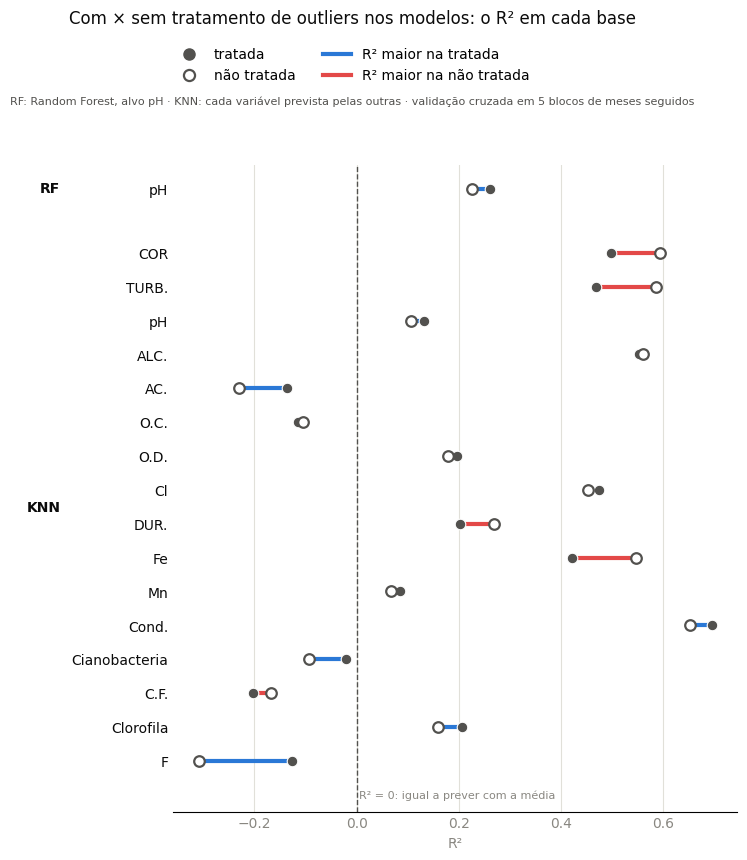

In [10]:
# R² de cada modelo e variável nas duas bases (só as linhas do R² da comparação)
halteres_r2(comparacao, plot=True, salvar=False)

# Gravação
Abas `rf`, `knn`, `previsoes_rf` e `previsoes_knn` (como no notebook da tratada), aba `comparacao` (uma linha por modelo × métrica × variável) e aba `meses_ganhos`. Como o RF usa random_state=42 e o KNN não tem sorteio, rodar de novo dá os mesmos números.

In [11]:
caminho = BASE_DIR / "data" / "output" / "ML_outliers_nao_tratados.xlsx"

# ExcelWriter permite gravar várias abas no mesmo arquivo
with pd.ExcelWriter(caminho) as arquivo:
    resultado_rf.to_excel(arquivo, sheet_name="rf", index=False)
    resultado_knn.to_excel(arquivo, sheet_name="knn", index=False)
    previsoes_rf.to_excel(arquivo, sheet_name="previsoes_rf", index=False)
    previsoes_knn.to_excel(arquivo, sheet_name="previsoes_knn", index=False)
    comparacao.to_excel(arquivo, sheet_name="comparacao", index=False)
    meses_ganhos.to_excel(arquivo, sheet_name="meses_ganhos", index=False)

print("Gravado em:", caminho)

Gravado em: C:\_Master\Programacao\Guilherme-Betta\1_Projects\IC2\IC2-item-5-figura\data\output\ML_outliers_nao_tratados.xlsx
